# Question 3

## Setup

In [1]:
from pathlib import Path
import os
import re
import unicodedata
import warnings
import zipfile
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from gensim.models import Phrases
from gensim.models.phrases import Phraser
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud

warnings.filterwarnings('ignore')
for resource in ['punkt_tab', 'averaged_perceptron_tagger_eng', 'wordnet',
                 'omw-1.4', 'stopwords']:
    nltk.download(resource, quiet=True)

# Folder layout: notebooks/ (this folder), ../data, ../deployment; plots go to outputs/
DATA_DIR = Path('../data')
OUT_DIR = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 70)

## 3.1 Dataframe of research articles

In [2]:
ZIP_PATH = DATA_DIR / 'research_corpus.zip'
CORPUS_DIR = DATA_DIR / 'research_corpus'

if os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(DATA_DIR)
if not os.path.isdir(CORPUS_DIR):
    raise FileNotFoundError(
        f"Could not find '{ZIP_PATH}' or a '{CORPUS_DIR}/' folder in the data folder.")

# Collect every .txt file
txt_files = []
for root, _, files in os.walk(CORPUS_DIR):
    for name in files:
        if name.endswith('.txt') and not name.startswith('.'):
            txt_files.append(os.path.join(root, name))


def article_number(path):
    match = re.search(r'(\d+)', os.path.basename(path))
    return int(match.group(1)) if match else float('inf')

txt_files.sort(key=article_number)

records = []
for path in txt_files:
    with open(path, 'r', encoding='utf-8', errors='replace') as f:
        content = f.read()
    records.append({
        'article_id': article_number(path),
        'filename': os.path.basename(path),
        'content': content,
    })

df_corpus = pd.DataFrame(records)

### Titles and basic statistics

In [3]:
PERSON_NAME_RE = re.compile(r"^[A-Z][a-z]+(\s[A-Z]\.)*(\s[A-Z][a-z'-]+)+$")


def split_front_matter(text, max_title_lines=6):
    """return the title and the number of lines in the title."""
    lines = [l.strip() for l in text.splitlines()]
    title_lines = []
    for i, line in enumerate(lines[:max_title_lines + 1]):
        if not line:
            continue
        if (PERSON_NAME_RE.match(line) or line.lower() == 'abstract'
                or re.search(r'University|College|Institute', line)):
            title = ' '.join(title_lines)
            return (title, i) if title else (None, 0)
        title_lines.append(line)
    return None, 0


def guess_title(text):
    title, _ = split_front_matter(text)
    if title:
        return title
    # No title in the file: describe it by the start of its first sentence
    body = re.sub(r'^\s*abstract\s*', '', text.strip(), flags=re.IGNORECASE)
    first_words = ' '.join(body.split()[:7])
    return f'[untitled] "{first_words}..."'


df_corpus['title'] = df_corpus['content'].apply(guess_title)
df_corpus['n_characters'] = df_corpus['content'].str.len()
df_corpus['n_words'] = df_corpus['content'].str.split().str.len()
df_corpus['n_lines'] = df_corpus['content'].str.count('\n') + 1

print(f"Total articles loaded: {len(df_corpus)}\n")
print(df_corpus[['article_id', 'filename', 'title', 'n_words', 'n_lines']]
      .to_string(index=False))

Total articles loaded: 5

 article_id       filename                                                                                    title  n_words  n_lines
          1 research_1.txt                                      [untitled] "The purposes of this article are to..."     5602      439
          2 research_2.txt Now I see it, now I don’t: researcher’s position and reflexivity in qualitative research     2416      176
          3 research_3.txt                  DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTIONAL DESIGN AND DEVELOPMENT     3828      368
          4 research_4.txt                          [untitled] "Cronbach’s alpha is a statistic commonly quoted..."     5922      123
          5 research_5.txt                Denzin’s Paradigm Shift: Revisiting Triangulation in Qualitative Research     4027      312


## 3.2 Denoise each article
### Stage A: structural denoising

In [4]:
def is_noise_line(line):
    """Titles, headings, author names, affiliations, running headers/footers and
    page numbers: short lines that start with a capital or digit, do not end a
    sentence and consist mostly of capitalised words or numbers."""
    words = line.split()
    if re.fullmatch(r'(?i)full size image|(article )?open access', line):   # web leftovers
        return True
    if not words or len(words) > 8 or line.endswith(('.', '?', '!', ',', ';', ':')):
        return False
    if words[0][0].islower():                    
        return False
    caps = sum(w[0].isupper() or w[0].isdigit() or not w[0].isalnum() for w in words)
    return caps >= 0.6 * len(words)


def structural_clean(text):
    """Stage A: readable, de-duplicated sentences (used for summarisation)."""
    text = unicodedata.normalize('NFKC', text).replace('﻿', '')        # unicode
    text = re.sub(r'[“”]', '"', re.sub(r'[‘’]', "'", text))
    _, n_title_lines = split_front_matter(text)                
    text = '\n'.join(text.splitlines()[n_title_lines:])
    text = re.sub(r'(?m)^(?i:key\s?words)\b.*(?:\n[a-z].*)*', ' ', text)     # keyword lists
    lines = [l.strip() for l in text.splitlines()]
    text = '\n'.join(l for l in lines if not is_noise_line(l))               # noise lines
    text = re.sub(r'(\w)-\n(\w)', r'\1\2', text)               
    text = re.sub(r'\s*\n\s*', ' ', text)                         
    text = re.sub(r'\([^()]*\b(1[89]|20)\d{2}[a-z]?\b[^()]*\)', ' ', text) 
    text = re.sub(r'([a-z][.,;]?)\d{1,2}(?=\s|$)', r'\1', text)   
    text = re.sub(r'\bet al\.?|https?://\S+|\S+@\S+|\be\.g\.,?|\bi\.e\.,?', ' ', text)
    text = re.sub(r'\s+([.,;:])', r'\1', re.sub(r'\s{2,}', ' ', text))

    # Sentence split; drop fragments and duplicates (research_1 has the same text twice)
    seen, sentences = set(), []
    for sent in nltk.sent_tokenize(text):
        key = re.sub(r'\W+', ' ', sent.lower()).strip()
        if len(key.split()) >= 4 and key not in seen:
            seen.add(key)
            sentences.append(sent)
    return sentences

### Stage B: linguistic denoising

In [5]:
lemmatizer = WordNetLemmatizer()
# English stopwords plus words that are frequent in any academic article
ACADEMIC_STOPWORDS = {
    'also', 'may', 'might', 'one', 'two', 'three', 'use', 'used', 'using', 'well',
    'however', 'thus', 'although', 'often', 'could', 'would', 'within', 'example',
    'article', 'paper', 'chapter', 'author', 'et', 'al', 'pp', 'see', 'eg', 'ie',
    'many', 'much', 'way', 'make', 'made', 'even', 'like', 'whether', 'must',
    'first', 'second', 'third', 'new', 'p', 'cf', 'yet', 'rather', 'among',
}
STOPWORDS = set(stopwords.words('english')) | ACADEMIC_STOPWORDS
POS_MAP = {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}


def linguistic_clean(sentence):
    """Stage B: lower-case letters only, POS-aware lemmatisation, no stopwords."""
    sentence = re.sub(r"'s\b", '', sentence.lower())
    tokens = nltk.word_tokenize(re.sub(r'[^a-z\s]', ' ', sentence))
    lemmas = [lemmatizer.lemmatize(tok, POS_MAP.get(tag[0], wordnet.NOUN))
              for tok, tag in nltk.pos_tag(tokens)]
    return [t for t in lemmas if t not in STOPWORDS and len(t) > 2]

### Apply both stages and detect multi-word expressions

In [6]:
df_corpus['sentences'] = df_corpus['content'].apply(structural_clean)
df_corpus['sentence_tokens'] = df_corpus['sentences'].apply(
    lambda sents: [linguistic_clean(s) for s in sents])

# Join frequent word pairs into one token
all_sentences = [toks for doc in df_corpus['sentence_tokens'] for toks in doc]
bigram = Phraser(Phrases(all_sentences, min_count=5, threshold=10, delimiter='_'))
df_corpus['sentence_tokens'] = df_corpus['sentence_tokens'].apply(
    lambda doc: [bigram[toks] for toks in doc])

df_corpus['clean_text'] = df_corpus['sentences'].apply(' '.join)
df_corpus['tokens'] = df_corpus['sentence_tokens'].apply(
    lambda doc: [t for toks in doc for t in toks])
df_corpus['clean_content'] = df_corpus['tokens'].apply(' '.join)

### Effect of the denoising process

In [7]:
print(pd.DataFrame({
    'raw words': df_corpus['n_words'].values,
    'clean words (A)': df_corpus['clean_text'].str.split().str.len().values,
    'tokens (B)': df_corpus['tokens'].str.len().values,
    'sentences': df_corpus['sentences'].str.len().values,
}, index=df_corpus['filename']))
print("\nExample output using research_1 :")
print("RAW:    ", re.sub(r'\s+', ' ', df_corpus['content'].iloc[0])[:250])
print("STAGE A:", df_corpus['clean_text'].iloc[0][:250])
print("STAGE B:", df_corpus['clean_content'].iloc[0][:250])

                raw words  clean words (A)  tokens (B)  sentences
filename                                                         
research_1.txt       5602             2600        1365         80
research_2.txt       2416             2198        1079         59
research_3.txt       3828             3585        1816        161
research_4.txt       5922             5713        2718        182
research_5.txt       4027             3561        1742        157

Example output using research_1 :
RAW:     The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner fo
STAGE A: The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosop

## 3.3 Summarising the first article using TextRank

In [8]:
first = df_corpus.iloc[0]
print(f"\n=== QUESTION 3.3: TEXTRANK SUMMARY OF {first['filename']} ===")
print(f"Title: {first['title']}")

# Candidate sentences: skip very short and very long ones 
candidates = [(i, s, toks) for i, (s, toks) in
              enumerate(zip(first['sentences'], first['sentence_tokens']))
              if 8 <= len(s.split()) <= 60 and len(toks) >= 4]
cand_text = [' '.join(toks) for _, _, toks in candidates]

tfidf_matrix = TfidfVectorizer().fit_transform(cand_text)
similarity = cosine_similarity(tfidf_matrix)
np.fill_diagonal(similarity, 0)

graph = nx.from_numpy_array(similarity)
textrank_scores = nx.pagerank(graph, weight='weight')

N_SUMMARY = 6
top_nodes = sorted(textrank_scores, key=textrank_scores.get, reverse=True)[:N_SUMMARY]
summary_nodes = sorted(top_nodes)                      # restore original order
summary = [candidates[n][1] for n in summary_nodes]

for n in summary_nodes:
    print(f"- [{textrank_scores[n]:.4f}] {candidates[n][1]}")

summary_words = sum(len(s.split()) for s in summary)
article_words = len(first['clean_text'].split())


=== QUESTION 3.3: TEXTRANK SUMMARY OF research_1.txt ===
Title: [untitled] "The purposes of this article are to..."
- [0.0269] The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.
- [0.0231] Both sets of purists view their paradigms as the ideal for research, and, implicitly if not explicitly, they advocate the incompatibility thesis, which posits that qualitative and quantitative research paradigms, including their associated methods, cannot and should not be mixed.
- [0.0281] Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.
- [0.0246] We hope the field will move beyond quantitative versus qualitative resear

### Visualisation 1: TextRank score of every sentence

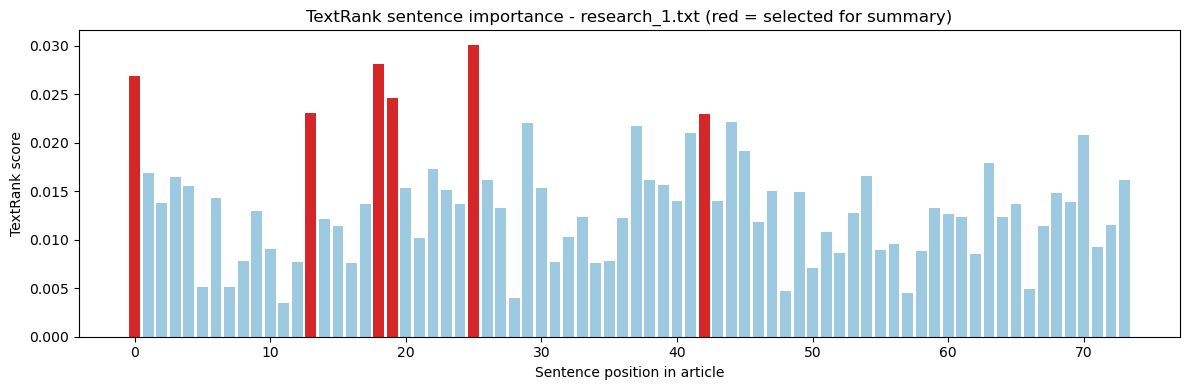

In [9]:
# Visualisation 1: TextRank score of every sentence, summary sentences highlighted
scores_in_order = [textrank_scores[n] for n in range(len(candidates))]
colors = ['#d62728' if n in top_nodes else '#9ecae1' for n in range(len(candidates))]
plt.figure(figsize=(12, 4))
plt.bar(range(len(candidates)), scores_in_order, color=colors)
plt.xlabel('Sentence position in article')
plt.ylabel('TextRank score')
plt.title(f'TextRank sentence importance - {first["filename"]} '
          f'(red = selected for summary)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q3_3_textrank_scores.png', dpi=150)
plt.show()

### Visualisation 2: key terms of the article

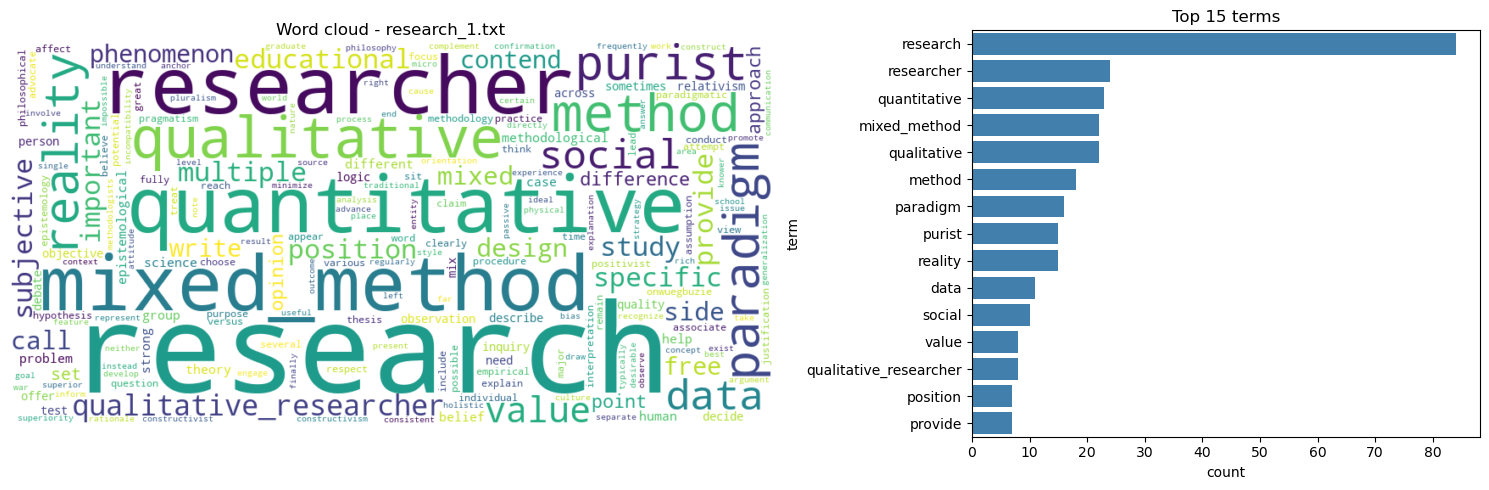

In [10]:
# Visualisation 2: key terms of the article
first_counts = Counter(first['tokens'])
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 2]})
wc = WordCloud(width=900, height=450, background_color='white', colormap='viridis',
               random_state=RANDOM_STATE).generate_from_frequencies(first_counts)
axes[0].imshow(wc, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title(f'Word cloud - {first["filename"]}')
top_terms = pd.DataFrame(first_counts.most_common(15), columns=['term', 'count'])
sns.barplot(data=top_terms, x='count', y='term', ax=axes[1], color='#3182bd')
axes[1].set_title('Top 15 terms')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q3_3_key_terms.png', dpi=150)
plt.show()

## 3.4 Aggregate summary of the remaining articles (TF-IDF)

In [11]:
remaining = df_corpus.iloc[1:].reset_index(drop=True)
short_names = {r.filename: f"{r.filename} - {r.title[:30]}" for r in remaining.itertuples()}

# text already tokenised and lemmatised (Stage B), so the vectoriser only splits on spaces
tfidf_vec = TfidfVectorizer(tokenizer=str.split, token_pattern=None,
                            lowercase=False, sublinear_tf=True)
article_tfidf = tfidf_vec.fit_transform(remaining['clean_content'])
tfidf_df = pd.DataFrame(article_tfidf.toarray(), index=remaining['filename'],
                        columns=tfidf_vec.get_feature_names_out())

print(f"=== QUESTION 3.4: TF-IDF SUMMARY OF {len(remaining)} ARTICLES ==")
print(f"TF-IDF matrix: {tfidf_df.shape[0]} articles x {tfidf_df.shape[1]} terms")

=== QUESTION 3.4: TF-IDF SUMMARY OF 4 ARTICLES ==
TF-IDF matrix: 4 articles x 1844 terms


### Shared themes and distinctive terms per article

In [12]:
corpus_terms = tfidf_df.mean().sort_values(ascending=False).head(15)
print("Key terms of the collection (mean TF-IDF across articles):")
print("  " + ", ".join(f"{t} ({w:.3f})" for t, w in corpus_terms.items()))

distinctive = {f: row.sort_values(ascending=False).head(8) for f, row in tfidf_df.iterrows()}
print("\nDistinctive terms per article (highest TF-IDF):")
for f, terms in distinctive.items():
    print(f"  {short_names[f]}: " + ", ".join(terms.index))

Key terms of the collection (mean TF-IDF across articles):
  research (0.072), study (0.066), knowledge (0.051), design (0.050), process (0.050), researcher (0.048), include (0.045), qualitative (0.045), analysis (0.044), concept (0.043), report (0.043), participant (0.042), development (0.042), data (0.042), address (0.041)

Distinctive terms per article (highest TF-IDF):
  research_2.txt - Now I see it, now I don’t: res: reflexivity, woman, immigrant, immigration, share, personal, participant, help
  research_3.txt - DEVELOPMENTAL RESEARCH: STUDIE: instructional, developmental_research, design_development, development, system, model, product, distinction
  research_4.txt - [untitled] "Cronbach’s alpha i: cronbach_alpha, scale, item, alpha, measure, science_education, statistic, high
  research_5.txt - Denzin’s Paradigm Shift: Revis: denzin, mixed_method, data_triangulation, triangulation, methodological_triangulation, multiple_source, rich, social_change


### Aggregate text summary: sentences closest to the corpus centroid

In [13]:
centroid = np.asarray(article_tfidf.mean(axis=0))

# Candidate sentences: skip very short and very long ones
sentence_pool = pd.DataFrame(
    [(r.filename, s, ' '.join(toks))
     for r in remaining.itertuples()
     for s, toks in zip(r.sentences, r.sentence_tokens)
     if 10 <= len(s.split()) <= 45 and len(toks) >= 6],
    columns=['filename', 'sentence', 'tokens'])
sentence_pool['score'] = cosine_similarity(
    tfidf_vec.transform(sentence_pool['tokens']), centroid).ravel()

SENTS_PER_ARTICLE = 2
summary_34 = (sentence_pool.sort_values('score', ascending=False)
              .groupby('filename', sort=False).head(SENTS_PER_ARTICLE)
              .sort_index())                      

print("=== AGGREGATE SUMMARY OF THE REMAINING ARTICLES ===")
for f, group in summary_34.groupby('filename', sort=False):
    print(f"\n{short_names[f]}")
    for _, row in group.iterrows():
        print(f"  - [{row['score']:.3f}] {row['sentence']}")

summary_words = summary_34['sentence'].str.split().str.len().sum()
corpus_words = remaining['clean_text'].str.split().str.len().sum()
print(f"\nSummary length: {summary_words} words from {corpus_words} "
      f"({summary_words / corpus_words:.1%} of the cleaned articles, "
      f"{len(summary_34)} of {remaining['sentences'].str.len().sum()} sentences)")

=== AGGREGATE SUMMARY OF THE REMAINING ARTICLES ===

research_2.txt - Now I see it, now I don’t: res
  - [0.199] The main purpose of this article is to argue and illustrate that reflexivity in qualitative research is affected by whether the researcher is part of the researched and shares the participants' experience.
  - [0.200] This article discusses issues relative to reflexivity under varying types of researcher's personal experience with the world being studied and illustrates them using my own work.

research_3.txt - DEVELOPMENTAL RESEARCH: STUDIE
  - [0.167] Some Type 1 developmental studies reflect traditional evaluation orientations in which the development process is not addressed, and only the product or program evaluation is described.
  - [0.169] Regardless of the nature of the Type 1 study, the results are typically context and product specific, even though the implications for similar situations may be discussed.

research_4.txt - [untitled] "Cronbach’s alpha i
  - [0.193

### Visualisation 1: key terms of the collection

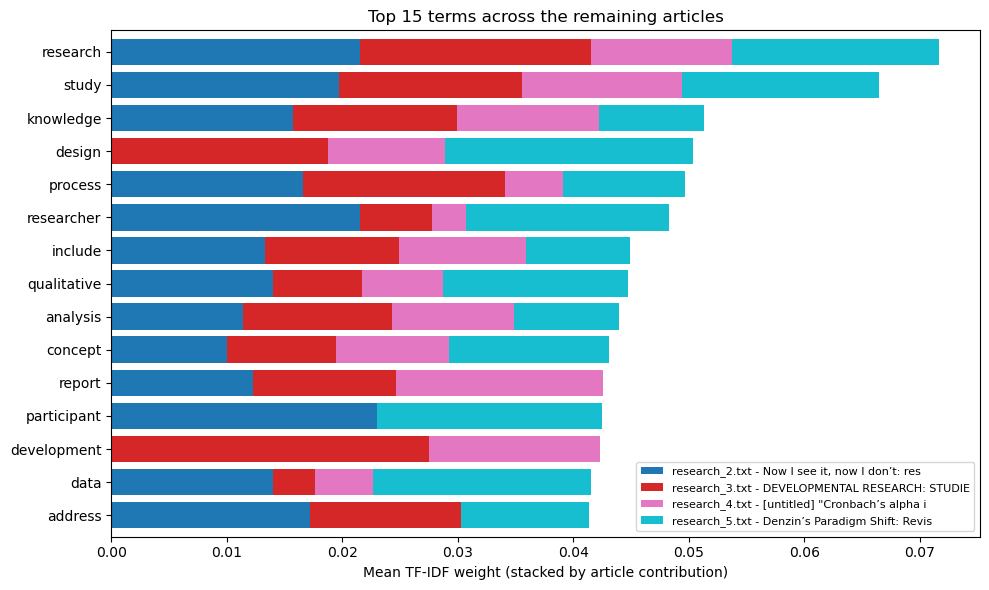

In [14]:
contrib = (tfidf_df[corpus_terms.index] / len(tfidf_df)).T.iloc[::-1]
contrib.columns = [short_names[f] for f in contrib.columns]
ax = contrib.plot.barh(stacked=True, figsize=(10, 6), colormap='tab10', width=0.8)
ax.set_xlabel('Mean TF-IDF weight (stacked by article contribution)')
ax.set_title('Top 15 terms across the remaining articles')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q3_4_corpus_terms.png', dpi=150)
plt.show()

### Visualisation 2: distinctive terms per article

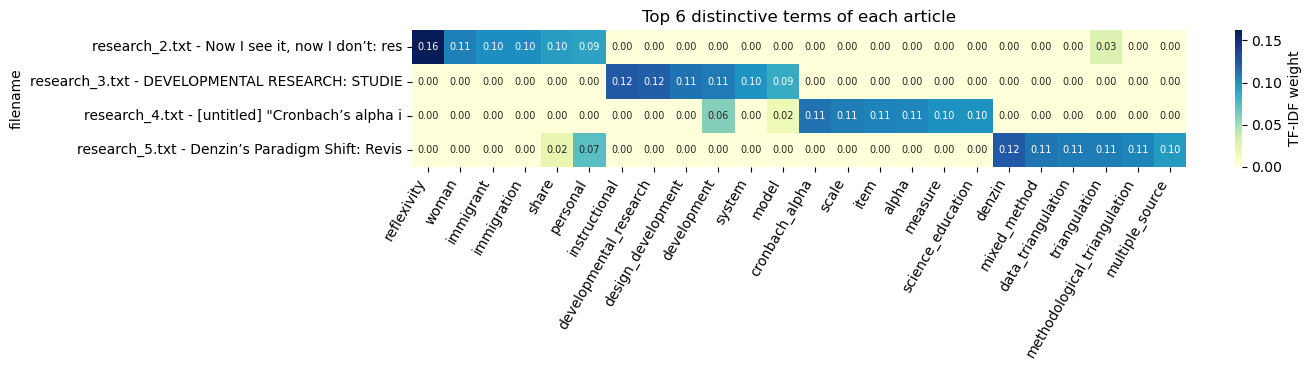

In [15]:
heat_terms = list(dict.fromkeys(t for terms in distinctive.values() for t in terms.index[:6]))
heat = tfidf_df[heat_terms].rename(index=short_names)
plt.figure(figsize=(14, 3.8))
sns.heatmap(heat, cmap='YlGnBu', annot=True, fmt='.2f', annot_kws={'size': 7},
            cbar_kws={'label': 'TF-IDF weight'})
plt.title('Top 6 distinctive terms of each article')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q3_4_distinctive_terms.png', dpi=150)
plt.show()

### Visualisation 3: similarity between the articles

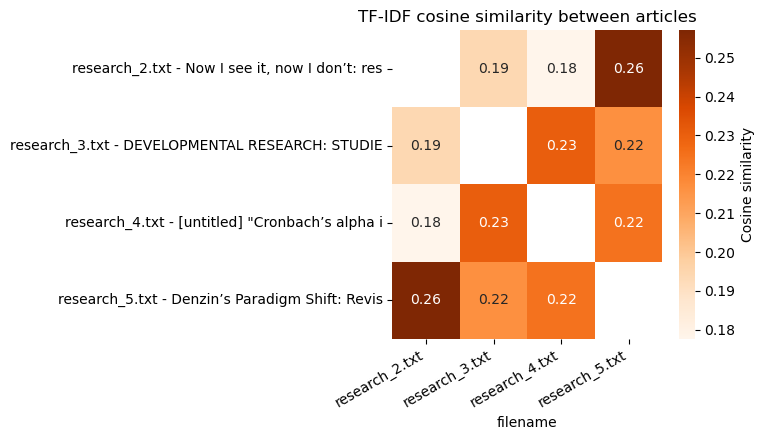

In [16]:
article_sim = pd.DataFrame(cosine_similarity(article_tfidf),
                           index=[short_names[f] for f in tfidf_df.index],
                           columns=tfidf_df.index)
plt.figure(figsize=(7.5, 4.5))
mask = np.eye(len(article_sim), dtype=bool)
sns.heatmap(article_sim, annot=True, fmt='.2f', cmap='Oranges', mask=mask,
            cbar_kws={'label': 'Cosine similarity'})
plt.title('TF-IDF cosine similarity between articles')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q3_4_article_similarity.png', dpi=150)
plt.show()

### Visualisation 4: TF-IDF word cloud per article

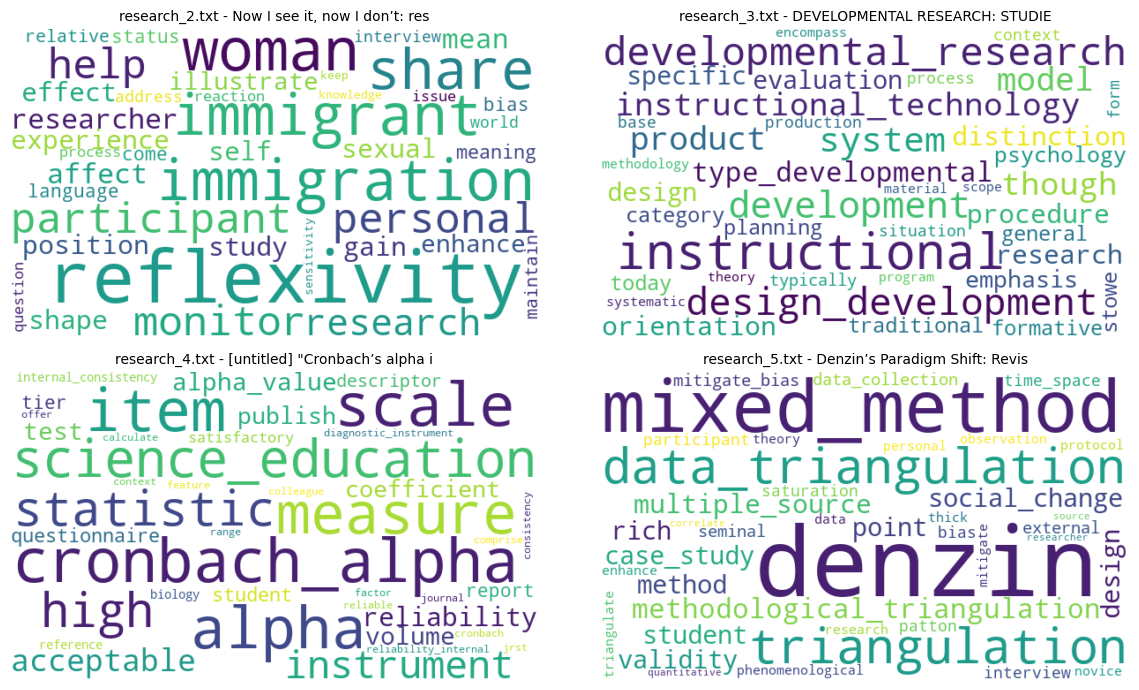

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (f, row) in zip(axes.ravel(), tfidf_df.iterrows()):
    weights = row[row > 0].sort_values(ascending=False).head(40).to_dict()
    ax.imshow(WordCloud(width=600, height=350, background_color='white',
                        colormap='viridis', random_state=RANDOM_STATE)
              .generate_from_frequencies(weights), interpolation='bilinear')
    ax.set_title(short_names[f], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q3_4_article_wordclouds.png', dpi=150)
plt.show()

## Saving the cleaned corpus for later use 

In [18]:
df_corpus.to_pickle(DATA_DIR / 'research_corpus_clean.pkl')
print(f"Saved {len(df_corpus)} corpus articles")

Saved 5 corpus articles
